# Pre/post log-ISI GMM fits vs autapse strength f (N250 variance-step run)

Variance-step run (`CPA_cusum_variance_N250_spikes.pickle`) at baseline noise variance 0, for variance steps
dH ∈ {5, 25, 50, 100, 200} pA² and f = 220–400 pA. A GMM with 2 or 3 components (lowest BIC) is fitted to log10 of the pooled pre- and
post-CP ISIs (all saved repeats) for each condition.

In [1]:
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
sns.set_theme()
warnings.filterwarnings('ignore')

from CPA_with_AQUA import *

In [2]:
tag = 'N250'
SAVE = False
VAR = 12.5                            # pA², baseline noise variance
DH_EX = [5, 25, 50, 100, 200]         # pA², variance steps (columns)
F_ALL = list(range(220, 401, 10))     # pA, all f fitted / summarised
F_GRID = list(range(220, 401, 20))    # pA, rows of the histogram grid (F_ALL works too, but 19 rows is tall)
T_DISCARD = 200                       # ms, initial transient
ISI_BINS = np.geomspace(10, 300, 61)  # ms
N_GMM = 3                             # max gaussian components; fits with 2..N_GMM are compared by BIC
C = {'pre': plt.cm.viridis(0.15), 'post': plt.cm.viridis(0.85)}

with open(f'CPA_cusum_variance_{tag}_spikes.pickle', 'rb') as file:
    saved = pickle.load(file)
T, true_cp, N_REP = saved['T'], saved['changepoint'], saved['N_repeats']
assert saved['change'] == 'variance' and VAR in saved['var']
assert set(DH_EX) <= set(saved['d_H']) and set(F_ALL) <= set(saved['f_values'])
print(f"repeats: {N_REP}, T = {T} ms, change point at {true_cp} ms")


def spikes(rep, dh, f):
    s = np.asarray(saved['spikes'][(rep, VAR, dh, f)], dtype = float)
    return s[~np.isnan(s)]


def pre_post_isis(dh, f):
    trials = [spikes(rep, dh, f) for rep in range(N_REP)]
    return reference_isis([(np.diff(s[s >= T_DISCARD]), s[s >= T_DISCARD][1:]) for s in trials], true_cp)

repeats: 250, T = 10500 ms, change point at 5500 ms


## 1. Fit GMM (2..N_GMM components, best by BIC) to pre and post log-ISIs

Components are numbered 1..N_GMM in order of increasing mean (1 = shortest / burst ISIs, N_GMM = longest / regular ISIs).
If fewer than N_GMM components win, the shortest fill slots 1.. and the longest fills slot N_GMM; the slots in between are NaN.
Density ratio = weight of component 1 / weight of component N_GMM.

In [3]:
gmms, rows = {}, []
for f in F_ALL:
    for dh in DH_EX:
        for period, isi in zip(['pre', 'post'], pre_post_isis(dh, f)):
            X = np.log10(isi)[:, None]
            fits = [GaussianMixture(k, n_init = 5, random_state = 0).fit(X) for k in range(2, N_GMM + 1)]
            gmm = min(fits, key = lambda g: g.bic(X))
            gmms[(f, dh, period)] = gmm
            order = np.argsort(gmm.means_.ravel())     # shortest to longest component
            mu, sd, w = gmm.means_.ravel()[order], np.sqrt(gmm.covariances_.ravel())[order], gmm.weights_[order]
            n = gmm.n_components
            slots = list(range(1, n)) + [N_GMM]          # longest always goes in the last slot, middle slots stay NaN
            row = {'f': f, 'dH': dh, 'period': period, 'n': len(isi), 'n components': n, 'density ratio': w[0] / w[-1]}
            for k in range(1, N_GMM + 1):
                row.update({f'mean {k}': np.nan, f'sd {k}': np.nan, f'weight {k}': np.nan})
            for j, k in enumerate(slots):
                row.update({f'mean {k}': 10**mu[j], f'sd {k}': sd[j], f'weight {k}': w[j]})
            rows.append(row)
gmm_fits = pd.DataFrame(rows)
gmm_fits.groupby(['period', 'n components']).size()

period  n components
post    2                7
        3               88
pre     3               95
dtype: int64

## 2. ISI distributions with GMM fits

Histograms as in `CPA_population_traces_variance` 1b'; the fitted log10-space density is converted to ISI space,
p(x) = p_log(log10 x) / (x ln 10), so it is on the same scale as `hist(density = True)`.

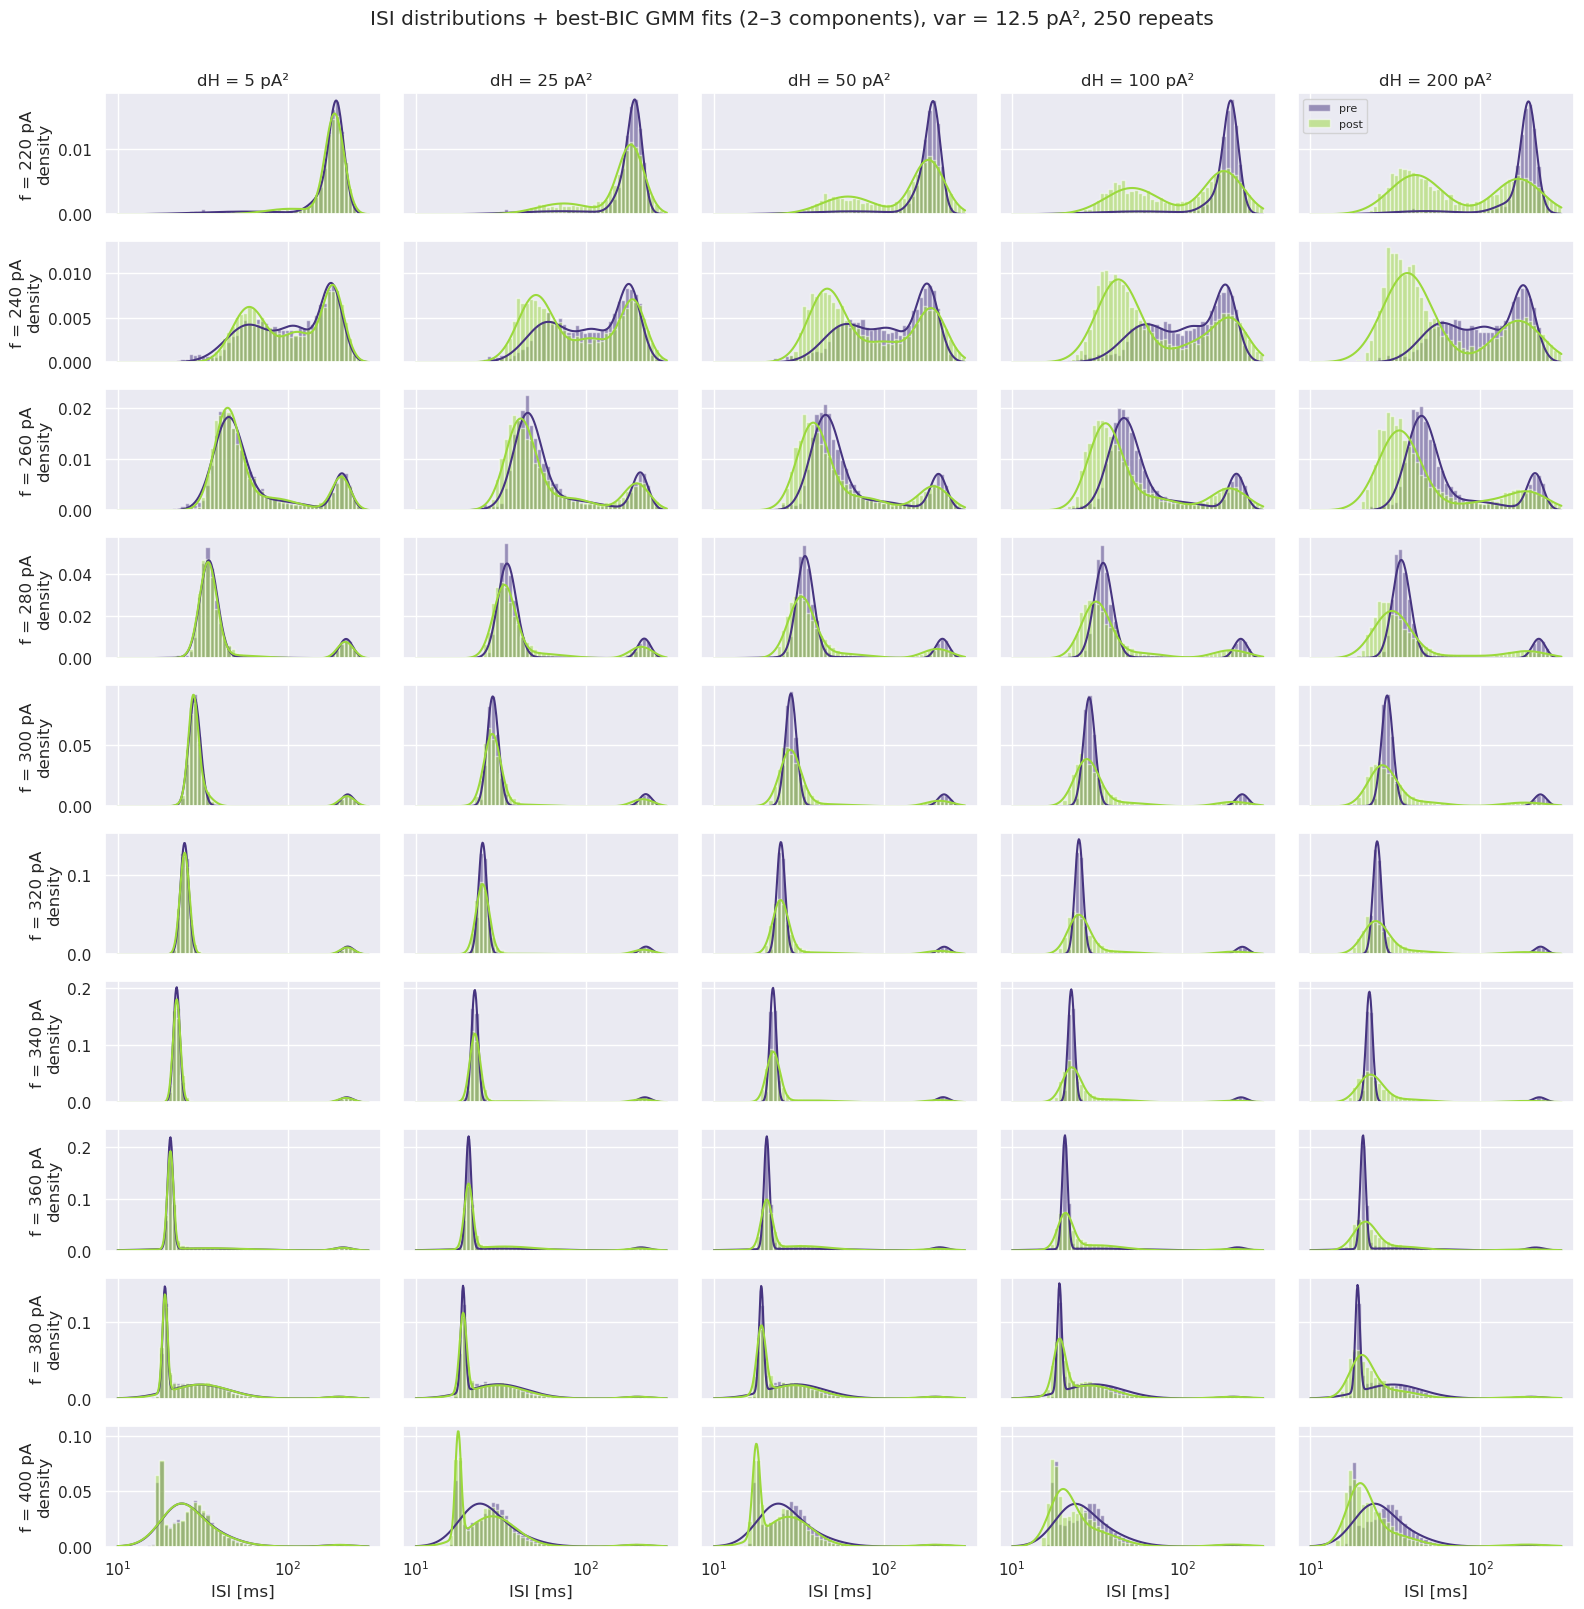

In [4]:
x = np.geomspace(ISI_BINS[0], ISI_BINS[-1], 400)
fig, ax = plt.subplots(len(F_GRID), len(DH_EX), figsize = (3.2*len(DH_EX), 1.6*len(F_GRID)), sharex = True, sharey = 'row')
for r, f in enumerate(F_GRID):
    for c, dh in enumerate(DH_EX):
        a = ax[r, c]
        for period, isi in zip(['pre', 'post'], pre_post_isis(dh, f)):
            a.hist(isi, bins = ISI_BINS, density = True, alpha = 0.5, color = C[period], label = period)
            pdf = np.exp(gmms[(f, dh, period)].score_samples(np.log10(x)[:, None])) / (x * np.log(10))
            a.plot(x, pdf, color = C[period], lw = 1.5)
        a.set_xscale('log')
        if r == 0: a.set_title(f'dH = {dh} pA²')
        if c == 0: a.set_ylabel(f'f = {f} pA\ndensity')
for a in ax[-1]: a.set_xlabel('ISI [ms]')
ax[0, -1].legend(fontsize = 8)
fig.suptitle(f'ISI distributions + best-BIC GMM fits (2–{N_GMM} components), var = {VAR:g} pA², {N_REP} repeats', y = 1.005)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_var_isi_gmm_grid.png', bbox_inches = 'tight')
plt.show()

## 3. GMM parameters vs f

As section 1d of `CPA_population_traces_variance`, with f on the x-axis. One row per component (1 = shortest mean ISI),
columns = mean, sd and weight. One colour per variance step; post solid, pre dashed
(pre should not depend on dH, so the dashed lines should overlap).

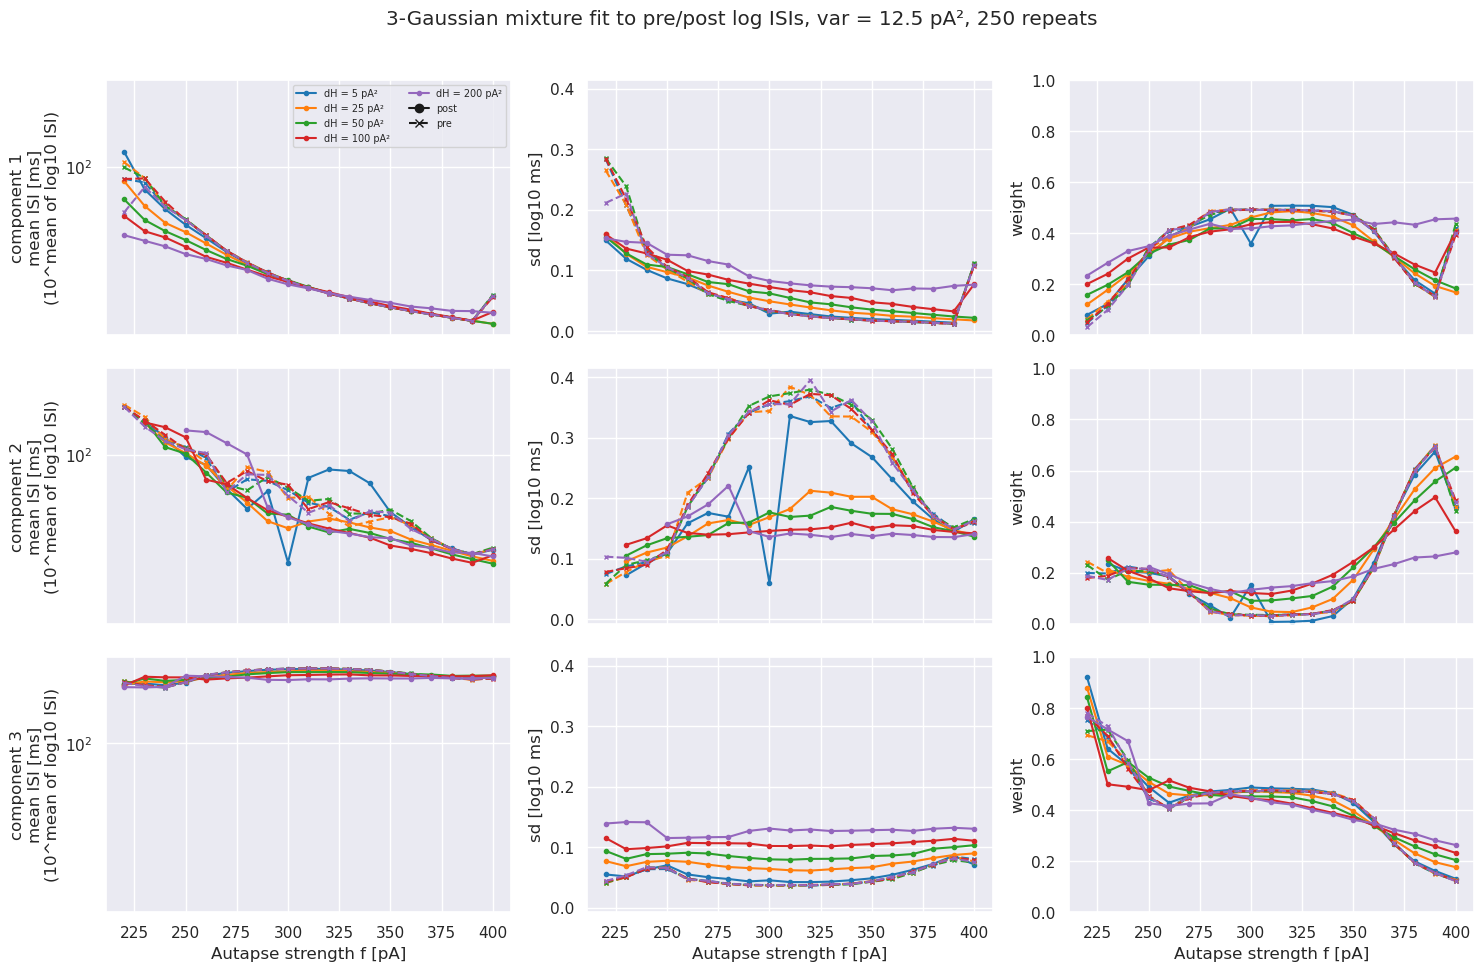

,f,dH,period,n,n components,density ratio,mean 1,sd 1,weight 1,mean 2,sd 2,weight 2,mean 3,sd 3,weight 3
0,220,5,pre,6789,3,0.064,87.440,0.284,0.048,170.048,0.075,0.199,196.138,0.043,0.752
1,220,5,post,6402,2,0.088,117.377,0.150,0.081,NaN,NaN,NaN,192.069,0.055,0.919
2,220,25,pre,6783,3,0.091,104.909,0.265,0.063,173.704,0.058,0.244,198.002,0.041,0.693
3,220,25,post,6636,2,0.138,85.080,0.159,0.121,NaN,NaN,NaN,190.272,0.077,0.879
4,220,50,pre,6797,3,0.085,99.057,0.285,0.060,170.364,0.059,0.231,198.219,0.041,0.709
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,400,50,post,18126,3,0.900,17.782,0.022,0.184,30.316,0.137,0.612,210.507,0.103,0.204
186,400,100,pre,23983,3,3.187,23.821,0.108,0.393,35.557,0.161,0.484,203.774,0.079,0.123
187,400,100,post,16843,3,1.743,20.247,0.077,0.405,33.230,0.142,0.362,211.373,0.111,0.232
188,400,200,pre,24035,3,3.310,24.167,0.109,0.402,35.487,0.163,0.476,205.395,0.076,0.122


In [5]:
DH_COLORS = dict(zip(DH_EX, sns.color_palette('tab10', len(DH_EX))))
LS = {'post': '-', 'pre': '--'}
MK = {'post': 'o', 'pre': 'x'}
fig, ax = plt.subplots(N_GMM, 3, figsize = (15, 3.2*N_GMM), sharex = True, sharey = 'col', squeeze = False)
for k in range(1, N_GMM + 1):
    a = ax[k - 1]
    for dh in DH_EX:
        for period in ['post', 'pre']:
            d = gmm_fits[(gmm_fits['dH'] == dh) & (gmm_fits['period'] == period)]
            kw = dict(color = DH_COLORS[dh], ls = LS[period], marker = MK[period], ms = 3)
            a[0].plot(d['f'], d[f'mean {k}'], label = f'dH = {dh} pA²' if period == 'post' else None, **kw)
            a[1].plot(d['f'], d[f'sd {k}'], **kw)
            a[2].plot(d['f'], d[f'weight {k}'], **kw)
    a[0].set_yscale('log')
    a[0].set_ylabel(f'component {k}\nmean ISI [ms]\n(10^mean of log10 ISI)')
    a[1].set_ylabel('sd [log10 ms]')
    a[2].set_ylabel('weight')
    a[2].set_ylim((0, 1))
for a in ax[-1]: a.set_xlabel('Autapse strength f [pA]')
ax[0, 0].plot([], [], 'k-o', label = 'post'); ax[0, 0].plot([], [], 'k--x', label = 'pre')
ax[0, 0].legend(fontsize = 7, ncol = 2)
fig.suptitle(f'{N_GMM}-Gaussian mixture fit to pre/post log ISIs, var = {VAR:g} pA², {N_REP} repeats', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_var_isi_gmm_params.png', bbox_inches = 'tight')
plt.show()
gmm_fits.round(3)

## 4. Pre/post mean firing rate difference and SNR vs f

Same definition as the PSTH rate change in `CPA_summary_plots.py`: trial-averaged PSTH (all repeats, `BIN` ms bins),
Δ rate = mean post − mean pre rate (pre from `T_DISCARD` to the CP), SNR = Δ rate / pooled SD of the pre and post PSTH bins.

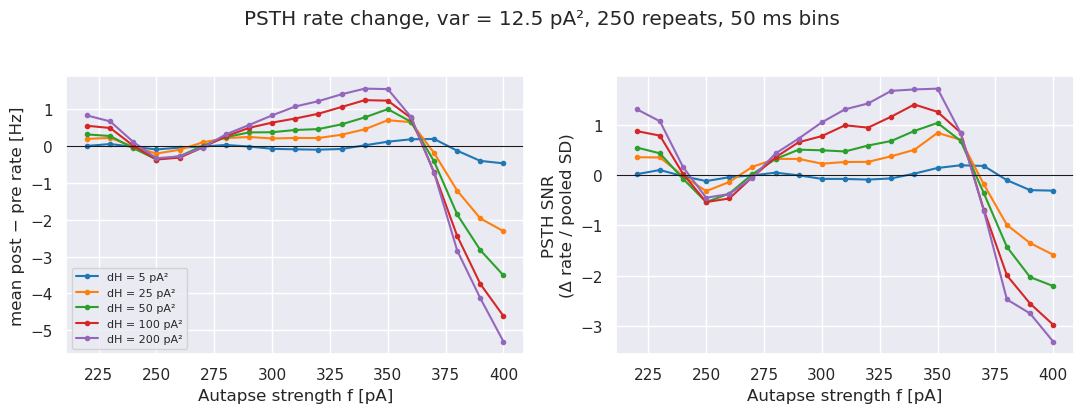

In [6]:
BIN = 50   # ms, PSTH bin
edges = np.arange(0, T + BIN, BIN)
t = 0.5*(edges[:-1] + edges[1:])
rows = []
for f in F_ALL:
    for dh in DH_EX:
        s = np.concatenate([spikes(rep, dh, f) for rep in range(N_REP)])
        rate = np.histogram(s, bins = edges)[0] / (N_REP * BIN/1000)
        pre, post = rate[(t > T_DISCARD) & (t < true_cp)], rate[t > true_cp]
        d, sd = post.mean() - pre.mean(), np.sqrt((pre.var() + post.var())/2)
        rows.append({'f': f, 'dH': dh, 'Δ rate': d, 'SNR': d/sd if sd > 0 else np.nan})
rates = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize = (11, 4), sharex = True)
for a, (y, ylabel) in zip(ax, [('Δ rate', 'mean post − pre rate [Hz]'), ('SNR', 'PSTH SNR\n(Δ rate / pooled SD)')]):
    for dh in DH_EX:
        d = rates[rates['dH'] == dh]
        a.plot(d['f'], d[y], '-o', ms = 3, color = DH_COLORS[dh], label = f'dH = {dh} pA²')
    a.axhline(0, color = 'k', lw = 0.8)
    a.set_xlabel('Autapse strength f [pA]')
    a.set_ylabel(ylabel)
ax[0].legend(fontsize = 8)
fig.suptitle(f'PSTH rate change, var = {VAR:g} pA², {N_REP} repeats, {BIN} ms bins', y = 1.03)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/{tag}_var_rate_snr.png', bbox_inches = 'tight')
plt.show()